# MAC-VQA Dataset Analysis (CV-STQA)

A fast, self-contained analysis of the MAC-VQA colonoscopy video-quality dataset. **No model training; no GPU needed.**
Expected run time on Kaggle: about 3-6 minutes (video metadata for all 1,000 clips, frames and photometric measurements for a subset that you can change in the configuration cell).

Inputs (as before): the Kaggle datasets *MAC-VQA Videos* and *VQA-MOS* (`MOS.txt`, columns `videoname,TSV,B,SR,S,U,O`).

What it produces (all figures saved as **EPS at 600 dpi** (figures that contain photos or heatmaps use 200 dpi inside the EPS to keep files small; their PNG is 600 dpi), plus PNG and PDF, with bold axes; tables saved as CSV):

1. Data integrity: clip count, MOS matching, missing values, duplicates.
2. MOS statistics and distributions of the six scores.
3. Relations between the scores (correlation matrices, attribute-vs-overall scatter).
4. Video properties (resolution, frame rate, length, frame count).
5. Sampled frames, 7x7 patch grid, patch montage, low / middle / high quality clips, best and worst clip per attribute.
6. Photometric measurements (brightness, saturation, sharpness, specular pixels, motion, ...) and how they correlate with each MOS.
7. Recording groups (file-name prefix): group sizes, how much of each score is explained by the group, and how often a random split puts the same group on both sides.
8. A zip with everything.

In [6]:
# ============================================================
# 1. Configuration, plotting style, helpers
# ============================================================
import os, time, json, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg") if os.environ.get("CVSTQA_HEADLESS") else None
import matplotlib.pyplot as plt
from scipy import stats
import cv2
warnings.filterwarnings("ignore")
T0 = time.time()

SEED            = 42
NUM_FRAMES      = 16       # frames sampled per clip (same as the model)
IMAGE_SIZE      = 224
GRID_SIZE       = 7
PHOTO_SUBSET    = 400      # clips used for photometric measurements (1000 = all, about 3x slower)
N_SPLIT_CHECK   = 200      # random 720/80/200 splits for the leakage check

INPUT_ROOT = Path(os.environ.get("CVSTQA_INPUT", "/kaggle/input"))
OUT  = Path(os.environ.get("CVSTQA_OUT", "/kaggle/working")) / "mac_vqa_dataset_analysis"
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)

COLS  = ["TSV", "B", "SR", "S", "U", "O"]
NAMES = {"TSV": "Temporal-spatial visibility", "B": "Brightness", "SR": "Specular reflection",
         "S": "Stability", "U": "Utility", "O": "Overall quality"}
# Muted palette (purple / orchid / green / steel blue / tan, as in the DARNet figures)
PURPLE, ORCHID, GREEN, BLUE, TAN, ROSE = "#6a5b94", "#9a6aa6", "#5b7f62", "#587ca3", "#c4a16e", "#b07a7f"
COLOR = {"TSV": PURPLE, "B": ORCHID, "SR": GREEN, "S": BLUE, "U": TAN, "O": ROSE}
INK = "#3a3a4a"
from matplotlib.colors import LinearSegmentedColormap
def seq(c): return LinearSegmentedColormap.from_list("seq", ["#f4f2f5", c])
DIV = LinearSegmentedColormap.from_list("div", [BLUE, "#f4f2f5", TAN])

DPI = 600
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 10,
    "axes.labelweight": "bold", "axes.titleweight": "bold", "axes.labelsize": 11, "axes.titlesize": 11,
    "axes.linewidth": 1.1, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False,
    "ps.fonttype": 42, "pdf.fonttype": 42, "savefig.bbox": "tight", "figure.dpi": 110})

def save_fig(fig, name, eps_dpi=DPI):
    """Bold tick labels on every axis, then save EPS + PNG (600 dpi) + PDF. Photo figures use eps_dpi=200."""
    fig.canvas.draw()
    for ax in fig.axes:
        for lab in ax.get_xticklabels() + ax.get_yticklabels():
            lab.set_fontweight("bold")
    # EPS/PDF: vector text and axes; embedded photos/heatmaps are resampled to eps_dpi to keep files small
    for ext in ("eps", "png", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", dpi=(eps_dpi if ext in ("eps", "pdf") else DPI) if ext != "png" else DPI, facecolor="white")
    print("saved", name)

def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index)

print("Output folder:", OUT)

Output folder: /kaggle/working/mac_vqa_dataset_analysis


## 2. Locate and parse the data

In [7]:
# ============================================================
# 2. Find files, parse MOS.txt, match clips
# ============================================================
VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv"}
videos, mos_files = [], []
for root, _, files in os.walk(INPUT_ROOT):
    for f in files:
        p = Path(root) / f
        if p.suffix.lower() in VIDEO_EXT: videos.append(p)
        if f.lower() == "mos.txt": mos_files.append(p)
assert len(mos_files) == 1, f"expected one MOS.txt, found {len(mos_files)}"
vids = [p for p in videos if p.parent.name.lower() == "videos"] or videos
lookup = {p.name: p for p in vids}

mos = pd.read_csv(mos_files[0], header=None, names=["video_id"] + COLS, skipinitialspace=True)
mos["video_id"] = mos["video_id"].astype(str).str.strip()
for c in COLS: mos[c] = pd.to_numeric(mos[c], errors="coerce")
mos["path"]  = mos["video_id"].map(lookup)
mos["group"] = mos["video_id"].str.replace(".mp4", "", regex=False).str.split("-").str[0]

integrity = pd.DataFrame({"check": ["video files found", "MOS records", "matched clips", "unmatched clips",
                                    "missing MOS values", "duplicate video ids", "recording groups (file-name prefix)"],
                          "value": [len(vids), len(mos), int(mos.path.notna().sum()), int(mos.path.isna().sum()),
                                    int(mos[COLS].isna().sum().sum()), int(mos.video_id.duplicated().sum()),
                                    mos.group.nunique()]})
display(integrity); save_table(integrity, "01_integrity", index=False)
mos = mos[mos.path.notna()].reset_index(drop=True)

,check,value
0,video files found,1000
1,MOS records,1000
2,matched clips,1000
3,unmatched clips,0
4,missing MOS values,0
5,duplicate video ids,0
6,recording groups (file-name prefix),72


## 3. MOS statistics and distributions

In [8]:
# ============================================================
# 3. Descriptive statistics
# ============================================================
desc = pd.DataFrame({
    "mean": mos[COLS].mean(), "std": mos[COLS].std(), "median": mos[COLS].median(),
    "min": mos[COLS].min(), "max": mos[COLS].max(),
    "q25": mos[COLS].quantile(.25), "q75": mos[COLS].quantile(.75),
    "skew": mos[COLS].skew(), "kurtosis": mos[COLS].kurt()}).round(3)
desc["shapiro_p"] = [stats.shapiro(mos[c])[1] for c in COLS]
display(desc); save_table(desc, "02_mos_statistics")
mos[["video_id"] + COLS + ["group"]].to_csv(TAB / "00_mos_clean.csv", index=False)

,mean,std,median,min,max,q25,q75,skew,kurtosis,shapiro_p
TSV,1.738,0.655,1.860,0.0,3.0,1.277,2.228,-0.452,-0.597,3.176220e-14
B,1.617,0.804,1.566,0.0,3.0,1.012,2.231,0.086,-0.932,1.164969e-14
SR,1.619,0.677,1.604,0.1,3.0,1.123,2.032,0.182,-0.620,8.121417e-10
S,1.550,0.777,1.667,0.0,3.0,0.947,2.164,-0.248,-0.964,1.144784e-14
U,1.722,0.718,1.715,0.0,3.0,1.323,2.290,-0.278,-0.429,1.777455e-11
O,3.075,1.012,3.122,1.0,5.0,2.356,3.832,-0.192,-0.786,6.580725e-12


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig01_MOS_distributions


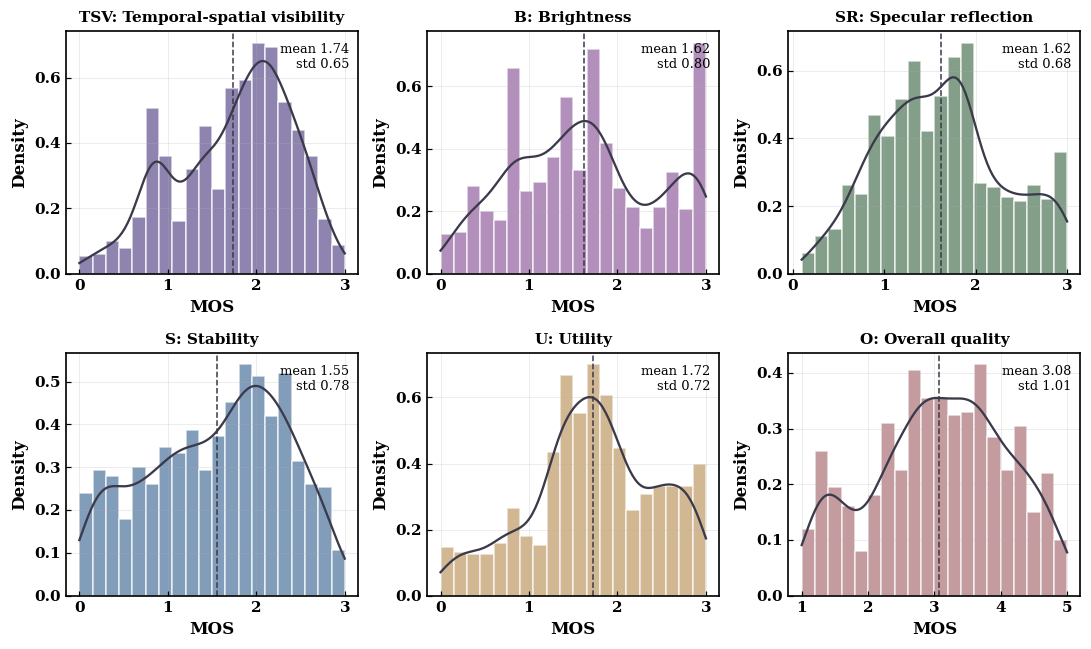

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig02_MOS_boxplots


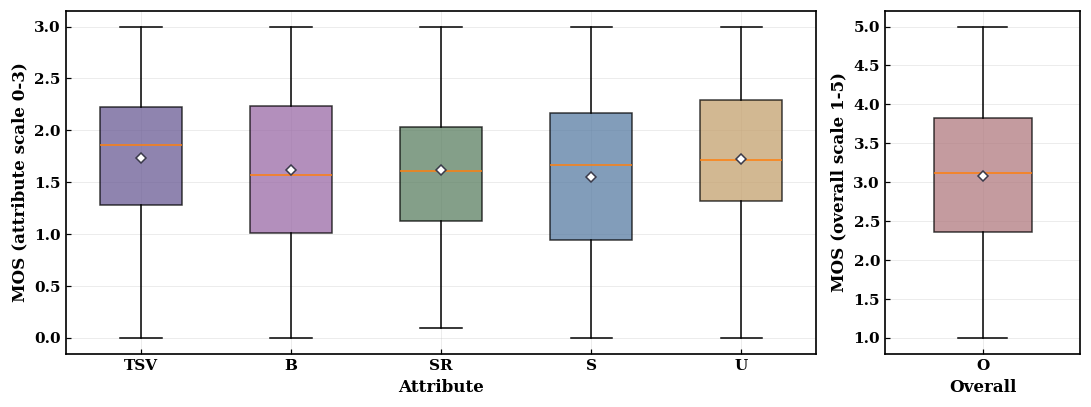

In [9]:
# ============================================================
# 4. Figure: MOS histograms with density curve (2 x 3)
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, c in zip(axes.ravel(), COLS):
    x = mos[c].values
    ax.hist(x, bins=20, color=COLOR[c], alpha=.75, edgecolor="white", density=True)
    xs = np.linspace(x.min(), x.max(), 200)
    ax.plot(xs, stats.gaussian_kde(x)(xs), color=INK, lw=1.5)
    ax.axvline(x.mean(), color=INK, ls="--", lw=1)
    ax.set_title(f"{c}: {NAMES[c]}", fontsize=10)
    ax.set_xlabel("MOS"); ax.set_ylabel("Density")
    ax.text(.97, .95, f"mean {x.mean():.2f}\nstd {x.std():.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=8.5)
fig.tight_layout(); save_fig(fig, "fig01_MOS_distributions"); plt.show()

# box + points
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [5, 1.3]})
att = COLS[:5]
bp = axes[0].boxplot([mos[c] for c in att], patch_artist=True, widths=.55, showmeans=True,
                     meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor=INK, markersize=5))
for b, c in zip(bp["boxes"], att): b.set_facecolor(COLOR[c]); b.set_alpha(.75)
axes[0].set_xticklabels(att); axes[0].set_ylabel("MOS (attribute scale 0-3)"); axes[0].set_xlabel("Attribute")
bp2 = axes[1].boxplot([mos["O"]], patch_artist=True, widths=.5, showmeans=True,
                      meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor=INK, markersize=5))
bp2["boxes"][0].set_facecolor(COLOR["O"]); bp2["boxes"][0].set_alpha(.75)
axes[1].set_xticklabels(["O"]); axes[1].set_ylabel("MOS (overall scale 1-5)"); axes[1].set_xlabel("Overall")
fig.tight_layout(); save_fig(fig, "fig02_MOS_boxplots"); plt.show()

## 5. Relations between the scores

saved fig03_MOS_correlation_matrices


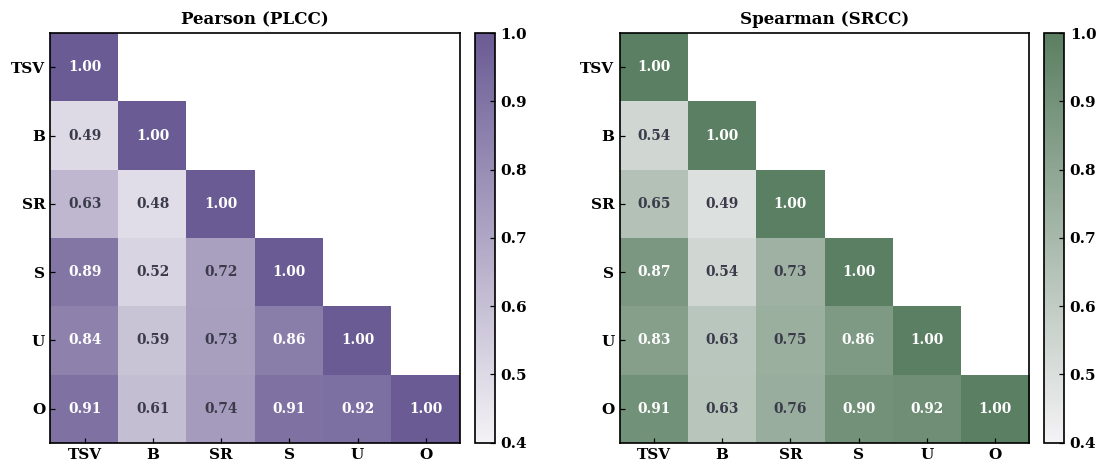

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig04_attribute_vs_overall


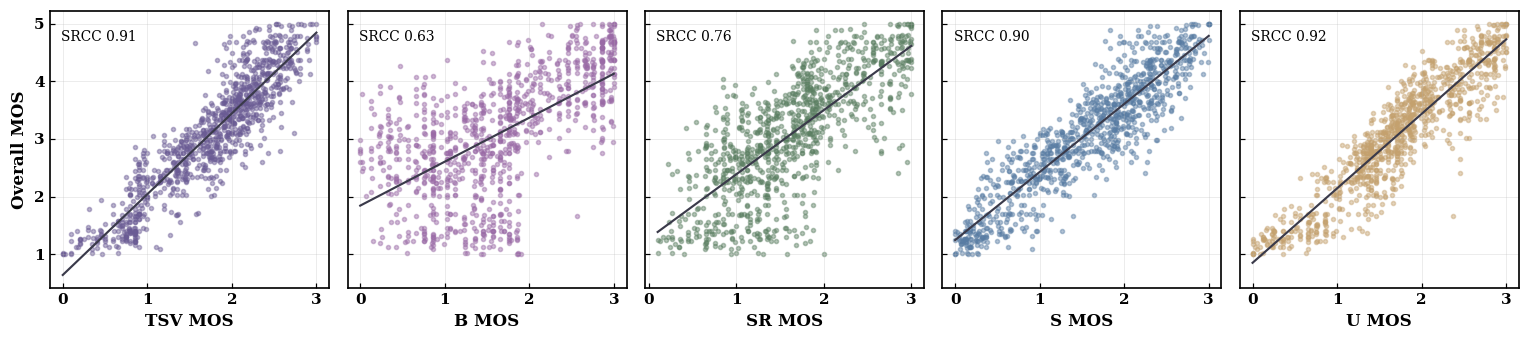

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig05_attribute_pair_matrix


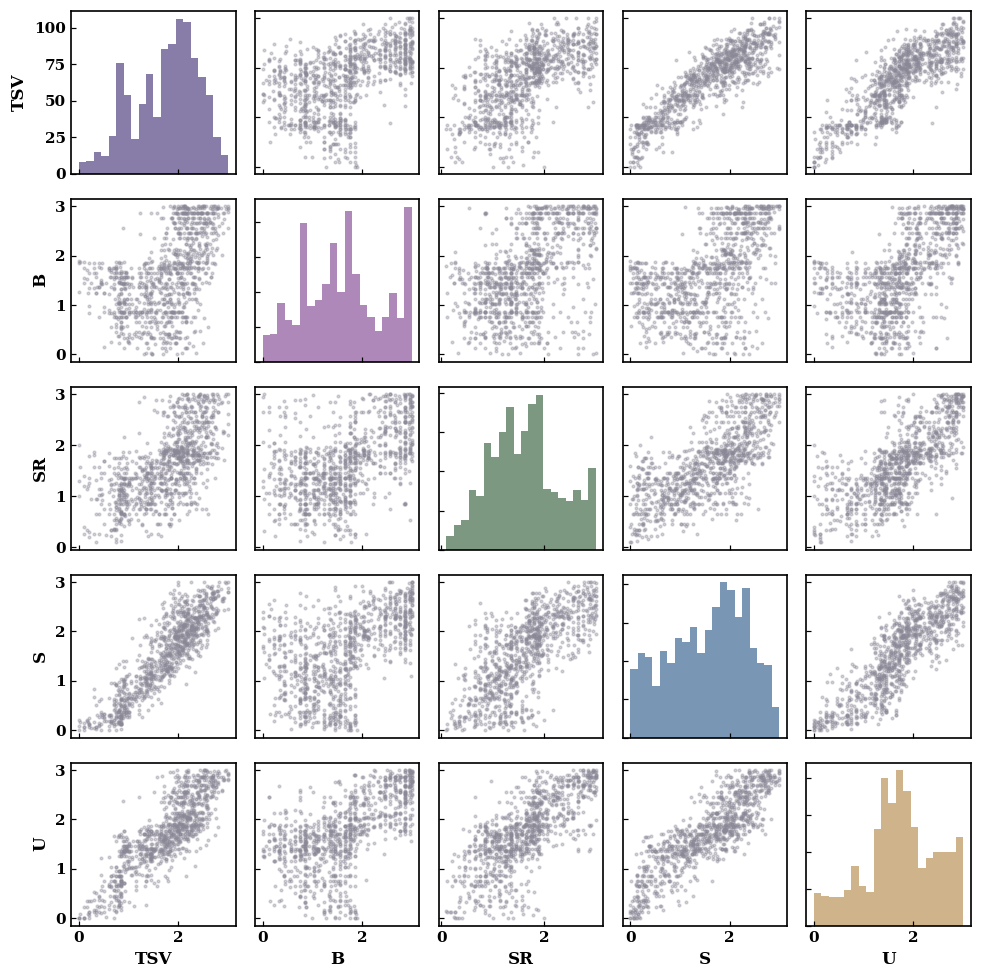

In [10]:
# ============================================================
# 5. Correlation matrices (Pearson and Spearman) + scatter vs overall
# ============================================================
pear, spear = mos[COLS].corr(), mos[COLS].corr(method="spearman")
save_table(pear.round(3), "03_corr_pearson"); save_table(spear.round(3), "03_corr_spearman")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for ax, M, t, col in zip(axes, (pear, spear), ("Pearson (PLCC)", "Spearman (SRCC)"), (PURPLE, GREEN)):
    V = M.values.copy(); lo = np.floor(V[np.tril_indices(6, -1)].min() * 10) / 10
    Vm = np.ma.masked_where(np.triu(np.ones((6, 6)), 1) > 0, V)
    im = ax.imshow(Vm, vmin=lo, vmax=1, cmap=seq(col))
    ax.set_xticks(range(6)); ax.set_xticklabels(COLS); ax.set_yticks(range(6)); ax.set_yticklabels(COLS)
    ax.grid(False); ax.set_title(t)
    for i in range(6):
        for j in range(i + 1):
            ax.text(j, i, f"{V[i, j]:.2f}", ha="center", va="center", fontsize=9, fontweight="bold",
                    color="white" if (V[i, j] - lo) / (1 - lo) > .6 else INK)
    fig.colorbar(im, ax=ax, fraction=.046, pad=.03)
fig.tight_layout(); save_fig(fig, "fig03_MOS_correlation_matrices", eps_dpi=200); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), sharey=True)
for ax, c in zip(axes, COLS[:5]):
    ax.scatter(mos[c], mos["O"], s=7, alpha=.45, color=COLOR[c])
    k, b = np.polyfit(mos[c], mos["O"], 1); xs = np.array([mos[c].min(), mos[c].max()])
    ax.plot(xs, k * xs + b, color=INK, lw=1.4)
    ax.set_xlabel(f"{c} MOS"); ax.text(.04, .93, f"SRCC {spear.loc[c,'O']:.2f}", transform=ax.transAxes, fontsize=9, va="top")
axes[0].set_ylabel("Overall MOS")
fig.tight_layout(); save_fig(fig, "fig04_attribute_vs_overall"); plt.show()

# pairwise scatter matrix of the five attributes
fig, axes = plt.subplots(5, 5, figsize=(9, 9))
for i, a in enumerate(COLS[:5]):
    for j, b in enumerate(COLS[:5]):
        ax = axes[i, j]
        if i == j: ax.hist(mos[a], bins=20, color=COLOR[a], alpha=.8)
        else: ax.scatter(mos[b], mos[a], s=3, alpha=.35, color="#8a8796")
        ax.grid(False)
        if i == 4: ax.set_xlabel(b)
        if j == 0: ax.set_ylabel(a)
        if i < 4: ax.set_xticklabels([])
        if j > 0: ax.set_yticklabels([])
fig.tight_layout(); save_fig(fig, "fig05_attribute_pair_matrix"); plt.show()

## 6. Video properties (metadata only, fast)

,mean,std,min,max
frames,254.48,7.52,232.00,284.00
fps,24.31,0.46,24.00,25.00
width,1240.44,23.60,1206.00,1272.00
height,1058.22,21.51,1024.00,1080.00
duration_s,10.47,0.24,9.64,11.50
size_MB,14.26,0.75,12.04,16.83


,clips
1264x1080,78
1262x1080,66
1266x1080,61
1260x1080,57
1214x1036,47
1222x1036,43
1258x1080,34
1222x1044,32
1214x1024,31
1216x1040,28


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig06_video_properties


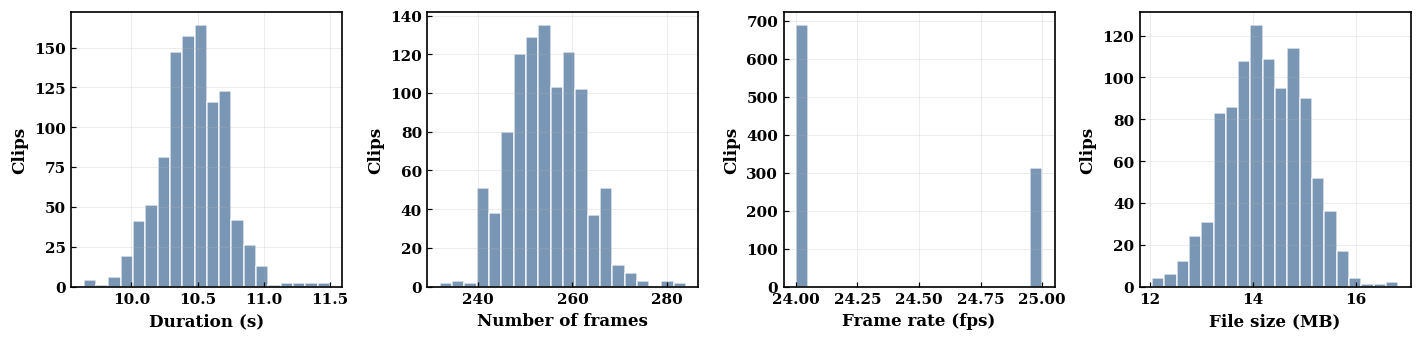

,TSV,B,SR,S,U,O
SRCC with duration,0.007,-0.023,-0.008,0.031,0.006,0.01


In [11]:
# ============================================================
# 6. Resolution, fps, frame count, duration for all clips
# ============================================================
rows = []
for p in mos.path:
    cap = cv2.VideoCapture(str(p))
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); fps = cap.get(cv2.CAP_PROP_FPS)
    rows.append(dict(frames=n, fps=fps, width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                     height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)), duration_s=n / fps if fps > 0 else np.nan,
                     size_MB=Path(p).stat().st_size / 1e6))
    cap.release()
meta = pd.DataFrame(rows); mos = pd.concat([mos, meta], axis=1)
vsum = meta.describe().T[["mean", "std", "min", "max"]].round(2); display(vsum); save_table(vsum, "04_video_properties")
res = (meta.width.astype(str) + "x" + meta.height.astype(str)).value_counts().rename("clips").to_frame()
display(res); save_table(res, "04_resolutions")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (c, t) in zip(axes, [("duration_s", "Duration (s)"), ("frames", "Number of frames"), ("fps", "Frame rate (fps)"), ("size_MB", "File size (MB)")]):
    ax.hist(meta[c].dropna(), bins=20, color=BLUE, alpha=.8, edgecolor="white"); ax.set_xlabel(t); ax.set_ylabel("Clips")
fig.tight_layout(); save_fig(fig, "fig06_video_properties"); plt.show()

# does clip length relate to quality?
rel = pd.DataFrame({c: [stats.spearmanr(mos["duration_s"], mos[c])[0]] for c in COLS}, index=["SRCC with duration"]).round(3)
display(rel); save_table(rel, "05_duration_vs_mos")

## 7. Frames, patches, and example clips

In [12]:
# ============================================================
# 7. Frame sampling helpers
# ============================================================
def sample_frames(path, n=NUM_FRAMES, size=IMAGE_SIZE):
    cap = cv2.VideoCapture(str(path)); total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    idx = np.linspace(0, total - 1, n).round().astype(int); out = []
    for i in idx:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, f = cap.read()
        if not ok: f = out[-1] if out else np.zeros((size, size, 3), np.uint8)
        else: f = cv2.cvtColor(cv2.resize(f, (size, size), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
        out.append(f)
    cap.release(); return np.stack(out), idx

def pick(col, q):  # clip at quantile q of a score (0 = lowest, 1 = highest)
    return mos.iloc[(mos[col].rank(method="first") - 1).sub(q * (len(mos) - 1)).abs().idxmin()]

Example clip: 8-3.mp4 | Overall MOS 3.12
saved fig07_sampled_frames


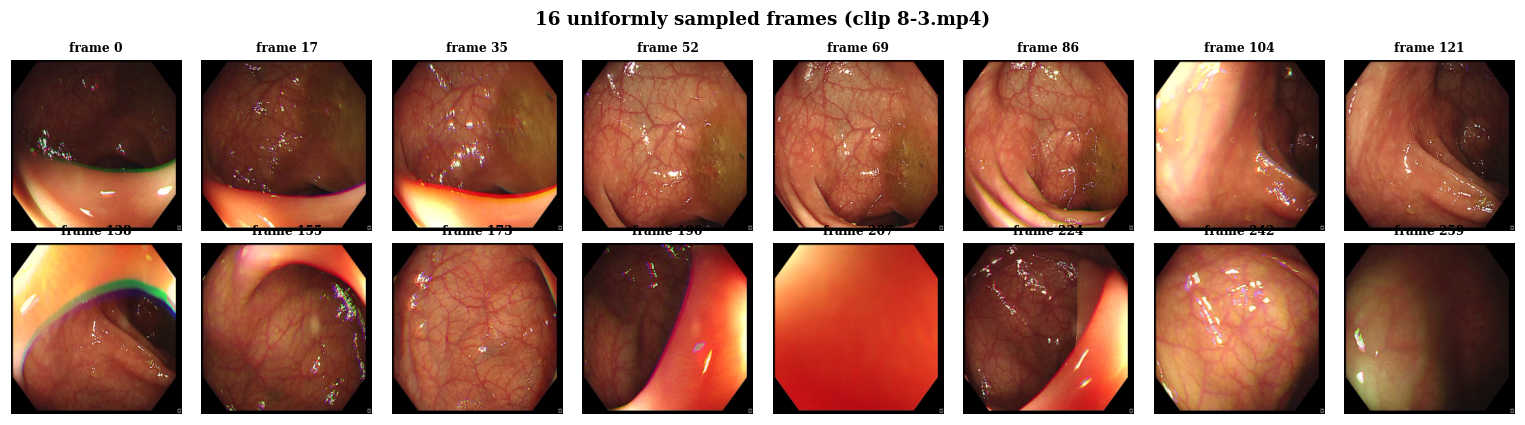

saved fig08_patch_grid


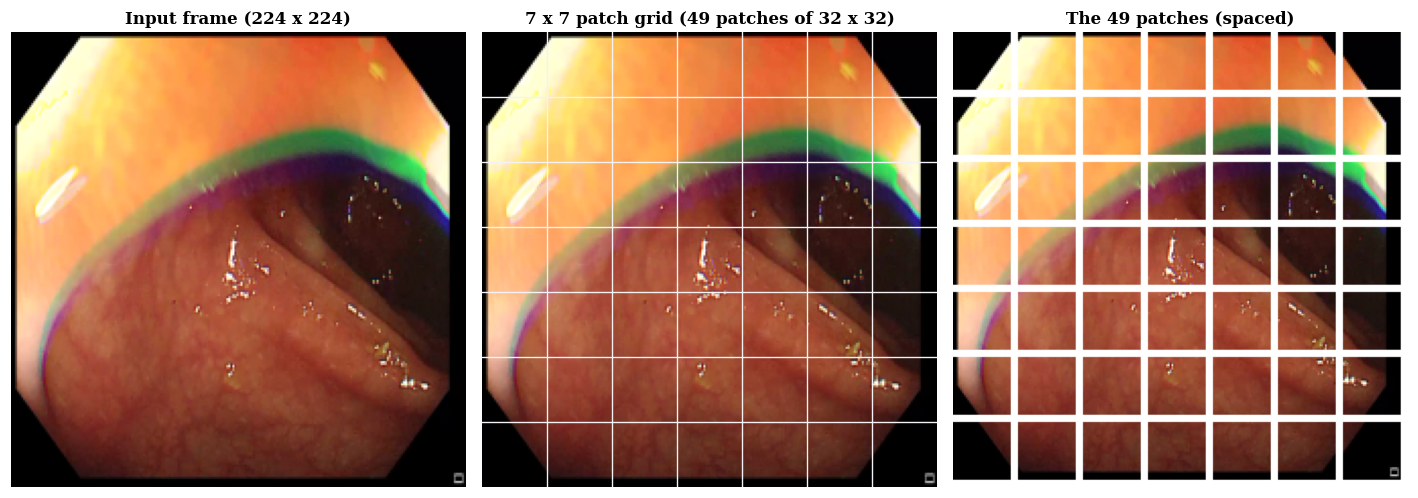

saved fig09_patch_level_maps


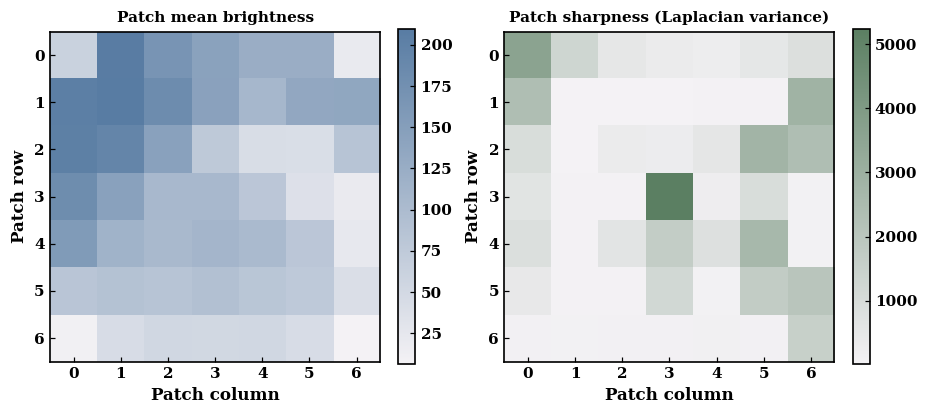

In [13]:
# ============================================================
# 8. 16 sampled frames, 7x7 grid, patch montage (one clip)
# ============================================================
ex = pick("O", .5)
frames, fidx = sample_frames(ex.path)
print("Example clip:", ex.video_id, "| Overall MOS", round(ex.O, 2))

fig, axes = plt.subplots(2, 8, figsize=(14, 3.9))
for a, f, i in zip(axes.ravel(), frames, fidx):
    a.imshow(f); a.set_title(f"frame {i}", fontsize=8); a.axis("off")
fig.suptitle(f"16 uniformly sampled frames (clip {ex.video_id})", fontweight="bold")
fig.tight_layout(); save_fig(fig, "fig07_sampled_frames", eps_dpi=200); plt.show()

f0 = frames[len(frames) // 2]; step = IMAGE_SIZE // GRID_SIZE
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
axes[0].imshow(f0); axes[0].set_title("Input frame (224 x 224)")
axes[1].imshow(f0)
for k in range(1, GRID_SIZE):
    axes[1].axhline(k * step - .5, color="#f4f2f5", lw=.9); axes[1].axvline(k * step - .5, color="#f4f2f5", lw=.9)
axes[1].set_title("7 x 7 patch grid (49 patches of 32 x 32)")
# patches separated by gaps
gap = 4; canvas = np.ones((GRID_SIZE * (step + gap), GRID_SIZE * (step + gap), 3), np.uint8) * 255
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        canvas[r * (step + gap): r * (step + gap) + step, c * (step + gap): c * (step + gap) + step] = f0[r*step:(r+1)*step, c*step:(c+1)*step]
axes[2].imshow(canvas); axes[2].set_title("The 49 patches (spaced)")
for a in axes: a.axis("off")
fig.tight_layout(); save_fig(fig, "fig08_patch_grid", eps_dpi=200); plt.show()

# patch-level brightness / sharpness map of that frame (what a patch scorer sees)
g = cv2.cvtColor(f0, cv2.COLOR_RGB2GRAY).astype(np.float32)
bm = np.array([[g[r*step:(r+1)*step, c*step:(c+1)*step].mean() for c in range(7)] for r in range(7)])
sm = np.array([[cv2.Laplacian(g[r*step:(r+1)*step, c*step:(c+1)*step], cv2.CV_32F).var() for c in range(7)] for r in range(7)])
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.8))
for ax, M, t, cm in zip(axes, (bm, sm), ("Patch mean brightness", "Patch sharpness (Laplacian variance)"), (seq(BLUE), seq(GREEN))):
    im = ax.imshow(M, cmap=cm); ax.set_title(t, fontsize=10); ax.grid(False)
    ax.set_xlabel("Patch column"); ax.set_ylabel("Patch row"); fig.colorbar(im, ax=ax, fraction=.046)
fig.tight_layout(); save_fig(fig, "fig09_patch_level_maps", eps_dpi=200); plt.show()

saved fig10_low_mid_high_overall


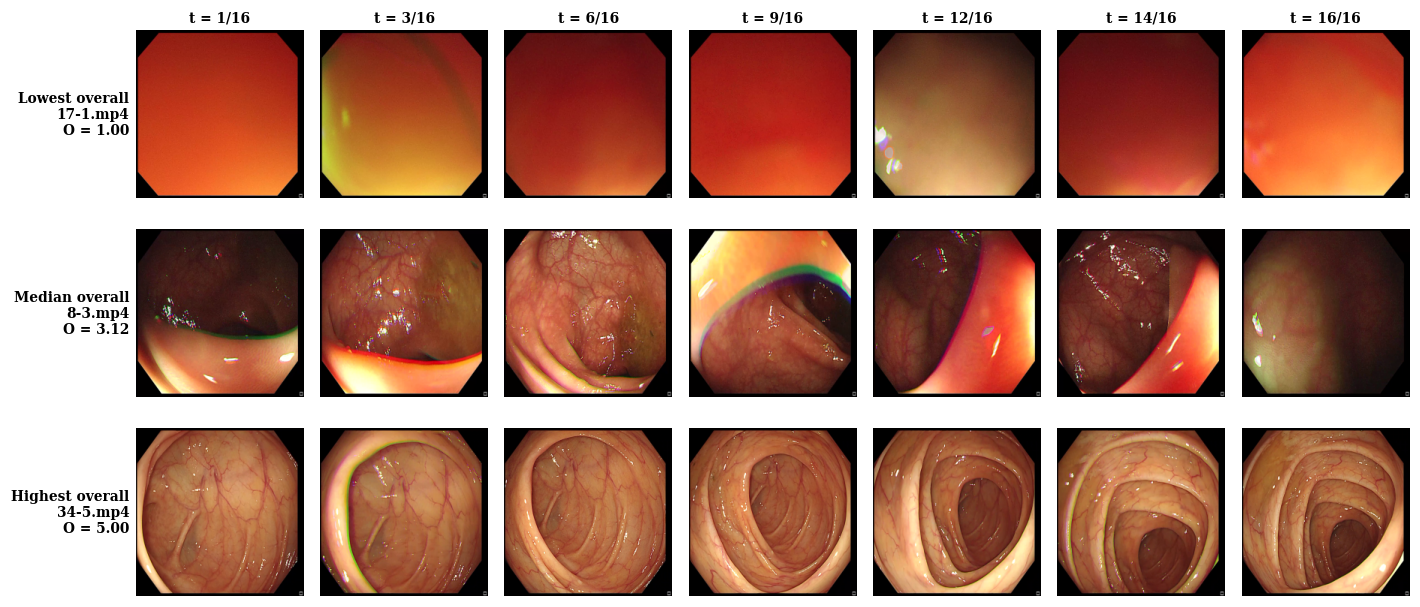

saved fig11_attribute_extremes


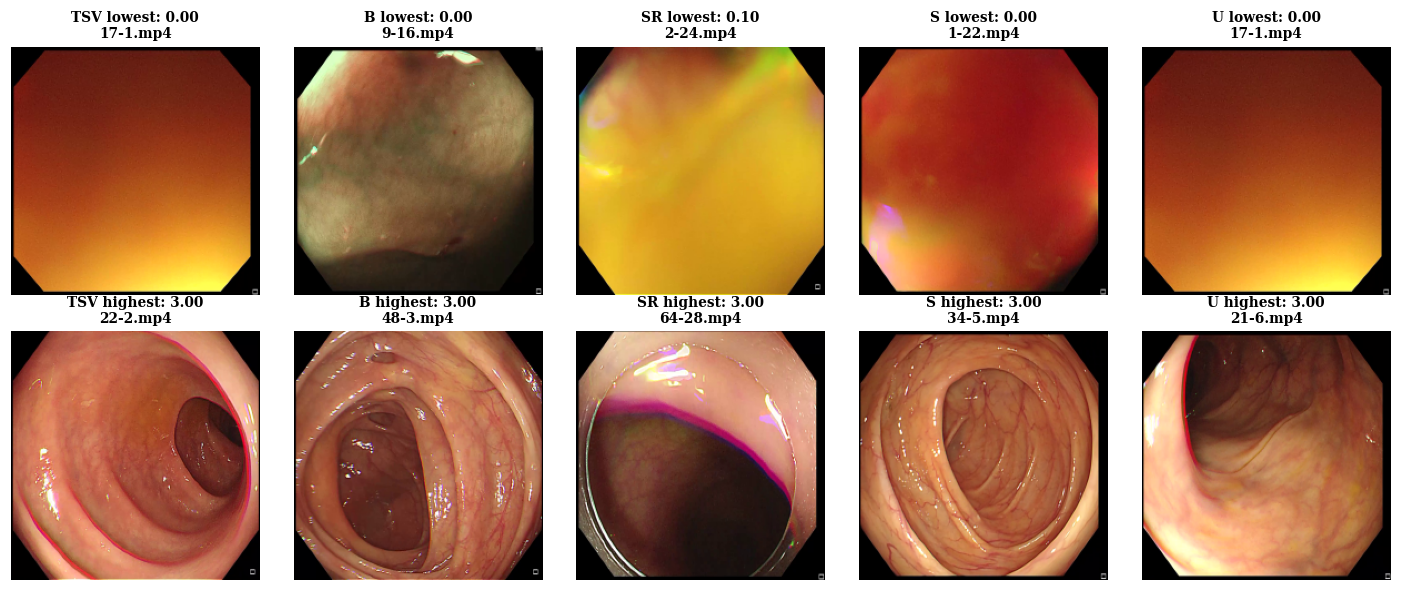

In [14]:
# ============================================================
# 9. Lowest / middle / highest overall quality clips
# ============================================================
quant = [(0.0, "Lowest"), (0.5, "Median"), (1.0, "Highest")]
show = [0, 2, 5, 8, 11, 13, 15]
fig, axes = plt.subplots(3, len(show), figsize=(13, 5.8))
for r, (q, nm) in enumerate(quant):
    row = pick("O", q); fr, fi = sample_frames(row.path)
    for c, k in enumerate(show):
        axes[r, c].imshow(fr[k]); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(f"t = {k+1}/16", fontsize=9)
    axes[r, 0].text(-.04, .5, f"{nm} overall\n{row.video_id}\nO = {row.O:.2f}", transform=axes[r, 0].transAxes,
                    ha="right", va="center", fontsize=9, fontweight="bold")
fig.tight_layout(); save_fig(fig, "fig10_low_mid_high_overall", eps_dpi=200); plt.show()

# lowest and highest clip for each attribute (middle frame)
fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
for c, col in enumerate(COLS[:5]):
    for r, (q, nm) in enumerate([(0.0, "lowest"), (1.0, "highest")]):
        row = pick(col, q); fr, _ = sample_frames(row.path, n=3)
        axes[r, c].imshow(fr[1]); axes[r, c].axis("off")
        axes[r, c].set_title(f"{col} {nm}: {row[col]:.2f}\n{row.video_id}", fontsize=9)
fig.tight_layout(); save_fig(fig, "fig11_attribute_extremes", eps_dpi=200); plt.show()

## 8. Photometric measurements vs MOS

In [15]:
# ============================================================
# 10. Simple per-clip photometric measurements (subset for speed)
# ============================================================
def measures(fr):
    gray = np.stack([cv2.cvtColor(f, cv2.COLOR_RGB2GRAY) for f in fr]).astype(np.float32)
    hsv  = np.stack([cv2.cvtColor(f, cv2.COLOR_RGB2HSV) for f in fr]).astype(np.float32)
    f32  = fr.astype(np.float32)
    hist = np.stack([np.bincount(g.astype(np.uint8).ravel(), minlength=256) for g in gray]).astype(np.float64)
    hist = hist / hist.sum(1, keepdims=True)
    ent  = -(hist * np.log2(hist + 1e-12)).sum(1).mean()
    return dict(
        Brightness      = gray.mean() / 255,
        Contrast        = gray.std(axis=(1, 2)).mean() / 255,
        Saturation      = hsv[..., 1].mean() / 255,
        Dark_fraction   = (gray < 40).mean(),
        Specular_frac   = ((gray > 235) & (hsv[..., 1] < 60)).mean(),
        Sharpness       = np.mean([cv2.Laplacian(g, cv2.CV_32F).var() for g in gray]),
        Gray_entropy    = ent,
        Red_green_ratio = (f32[..., 0].mean() / (f32[..., 1].mean() + 1e-6)),
        Motion          = np.abs(np.diff(gray, axis=0)).mean() / 255)

sub = mos.sample(min(PHOTO_SUBSET, len(mos)), random_state=SEED)
t1 = time.time(); recs = []
for i, (_, r) in enumerate(sub.iterrows()):
    fr, _ = sample_frames(r.path); m = measures(fr); m["video_id"] = r.video_id; recs.append(m)
    if (i + 1) % 100 == 0: print(f"  {i+1}/{len(sub)} clips, {time.time()-t1:.0f}s")
ph = pd.DataFrame(recs).merge(mos[["video_id"] + COLS], on="video_id")
MEAS = [c for c in ph.columns if c not in COLS + ["video_id"]]
save_table(ph, "06_photometric_per_clip", index=False)
display(ph[MEAS].describe().T[["mean", "std", "min", "max"]].round(4))

  100/400 clips, 312s
  200/400 clips, 614s
  300/400 clips, 966s
  400/400 clips, 1311s


,mean,std,min,max
Brightness,0.3814,0.0332,0.2684,0.4803
Contrast,0.2135,0.0193,0.1696,0.2744
Saturation,0.5952,0.0672,0.3172,0.7839
Dark_fraction,0.1735,0.0525,0.0688,0.4128
Specular_frac,0.0122,0.0086,0.0002,0.0591
Sharpness,849.4860,439.1298,271.6108,3741.9038
Gray_entropy,7.0255,0.1773,6.4123,7.4246
Red_green_ratio,1.6293,0.2049,1.1141,2.4935
Motion,0.1399,0.0353,0.0459,0.2582


,TSV,B,SR,S,U,O
Brightness,0.248,0.260,0.120,0.212,0.246,0.262
Contrast,0.342,-0.124,0.212,0.295,0.219,0.272
Saturation,-0.250,-0.070,-0.258,-0.284,-0.304,-0.313
Dark_fraction,-0.086,-0.356,-0.063,-0.094,-0.171,-0.146
Specular_frac,0.272,-0.004,0.194,0.179,0.225,0.250
Sharpness,0.517,0.184,0.184,0.534,0.455,0.486
Gray_entropy,0.457,0.065,0.262,0.451,0.407,0.420
Red_green_ratio,-0.125,0.157,0.014,-0.115,-0.078,-0.086
Motion,-0.046,-0.195,-0.252,-0.332,-0.193,-0.182


saved fig12_photometric_vs_MOS


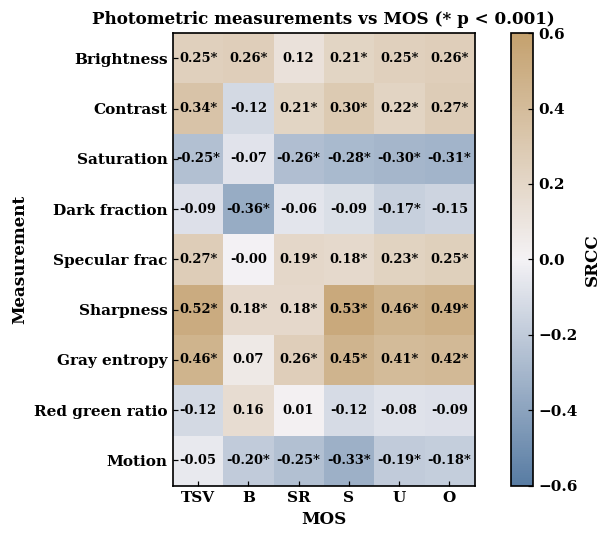

,best_measurement,abs_SRCC
TSV,Sharpness,0.517
B,Dark_fraction,0.356
SR,Gray_entropy,0.262
S,Sharpness,0.534
U,Sharpness,0.455
O,Sharpness,0.486


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig13_best_measurement_scatter


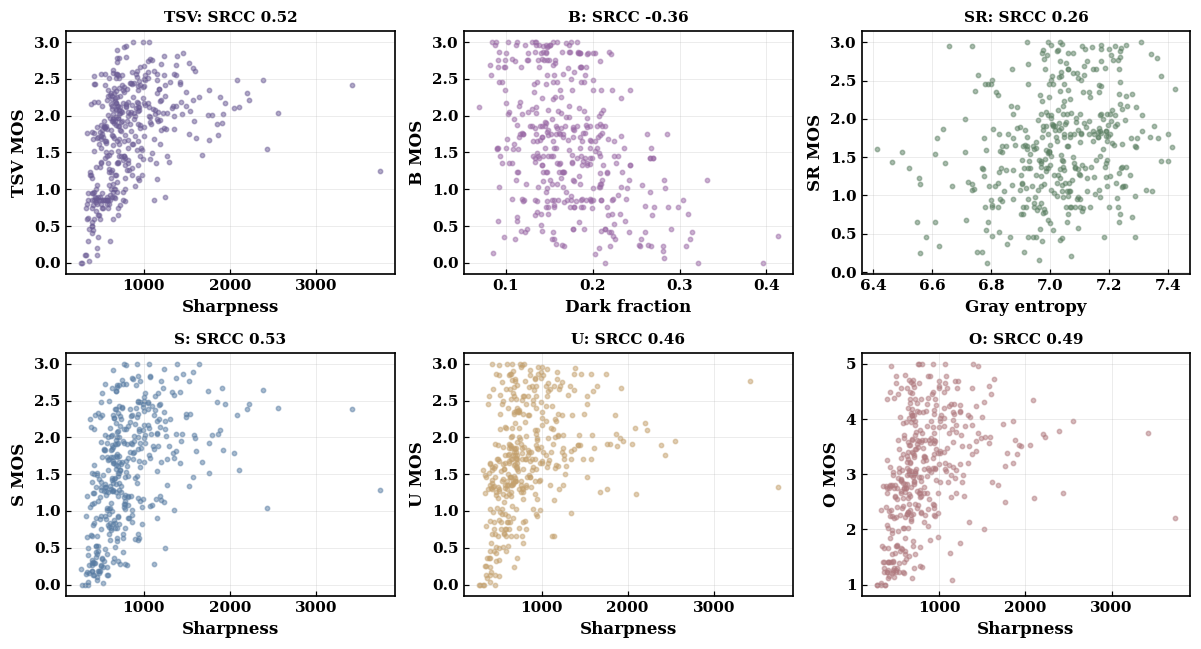

In [16]:
# ============================================================
# 11. Spearman correlation: measurements vs the six MOS
# ============================================================
R = pd.DataFrame({c: [stats.spearmanr(ph[m], ph[c])[0] for m in MEAS] for c in COLS}, index=MEAS)
P = pd.DataFrame({c: [stats.spearmanr(ph[m], ph[c])[1] for m in MEAS] for c in COLS}, index=MEAS)
save_table(R.round(3), "07_photometric_vs_mos_srcc"); save_table(P, "07_photometric_vs_mos_pvalue")
display(R.round(3))

fig, ax = plt.subplots(figsize=(7.4, 5))
im = ax.imshow(R.values, cmap=DIV, vmin=-.6, vmax=.6); ax.grid(False)
ax.set_xticks(range(6)); ax.set_xticklabels(COLS); ax.set_yticks(range(len(MEAS))); ax.set_yticklabels([m.replace("_", " ") for m in MEAS])
for i in range(len(MEAS)):
    for j in range(6):
        ax.text(j, i, f"{R.values[i,j]:.2f}" + ("*" if P.values[i, j] < .001 else ""), ha="center", va="center", fontsize=8.5, fontweight="bold")
ax.set_xlabel("MOS"); ax.set_ylabel("Measurement"); fig.colorbar(im, ax=ax, fraction=.046, label="SRCC")
ax.set_title("Photometric measurements vs MOS (* p < 0.001)")
fig.tight_layout(); save_fig(fig, "fig12_photometric_vs_MOS", eps_dpi=200); plt.show()

# best single predictor per score
best = pd.DataFrame({"best_measurement": R.abs().idxmax(), "abs_SRCC": R.abs().max().round(3)})
display(best); save_table(best, "08_best_single_measurement")

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, c in zip(axes.ravel(), COLS):
    m = R[c].abs().idxmax(); ax.scatter(ph[m], ph[c], s=8, alpha=.5, color=COLOR[c])
    ax.set_xlabel(m.replace("_", " ")); ax.set_ylabel(f"{c} MOS"); ax.set_title(f"{c}: SRCC {R.loc[m, c]:.2f}", fontsize=10)
fig.tight_layout(); save_fig(fig, "fig13_best_measurement_scatter"); plt.show()

## 9. Recording groups and split leakage

72 groups | clips per group: mean 13.9, min 2, max 49


,eta_squared
TSV,0.402
B,0.237
SR,0.279
S,0.384
U,0.375
O,0.394


Random splits: 99.9% of test clips (min 98.5%) share a file-name group with a training clip


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig14_groups_and_leakage


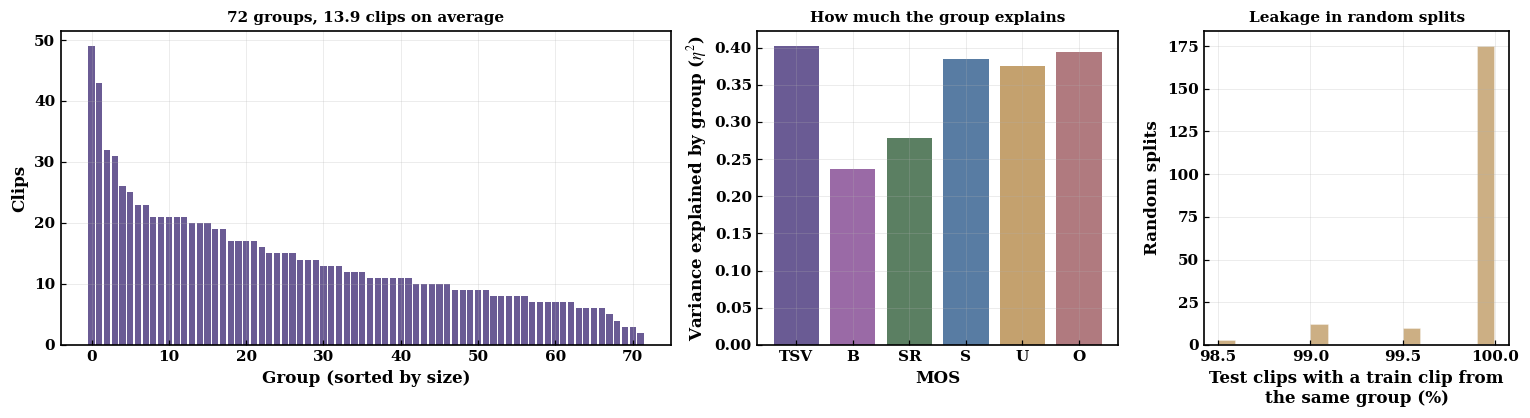

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig15_overall_by_group


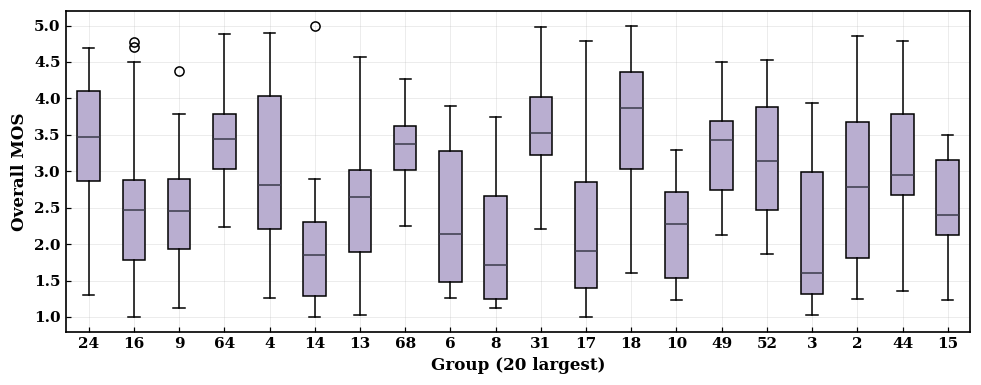

In [17]:
# ============================================================
# 12. Groups (file-name prefix): sizes, variance explained, leakage of random splits
# ============================================================
gs = mos.groupby("group").size().sort_values(ascending=False)
print(f"{len(gs)} groups | clips per group: mean {gs.mean():.1f}, min {gs.min()}, max {gs.max()}")
save_table(gs.rename("clips").to_frame(), "09_group_sizes")

def eta2(col):   # share of variance explained by group
    g = mos.groupby("group")[col]; ssb = (g.count() * (g.mean() - mos[col].mean()) ** 2).sum()
    return ssb / ((mos[col] - mos[col].mean()) ** 2).sum()
E = pd.Series({c: eta2(c) for c in COLS}, name="eta_squared").round(3).to_frame(); display(E); save_table(E, "10_group_variance_explained")

# leakage: fraction of test clips whose group also appears in training (720/80/200)
rng = np.random.default_rng(SEED); frac = []
grp = mos.group.values
for _ in range(N_SPLIT_CHECK):
    perm = rng.permutation(len(mos)); tr, te = perm[:720], perm[800:]
    frac.append(np.isin(grp[te], np.unique(grp[tr])).mean())
frac = np.array(frac)
print(f"Random splits: {100*frac.mean():.1f}% of test clips (min {100*frac.min():.1f}%) share a file-name group with a training clip")
save_table(pd.DataFrame({"fraction_test_clips_with_group_in_train": frac}), "11_leakage_per_split", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), gridspec_kw={"width_ratios": [2.2, 1.3, 1.1]})
axes[0].bar(range(len(gs)), gs.values, color=PURPLE); axes[0].set_xlabel("Group (sorted by size)"); axes[0].set_ylabel("Clips")
axes[0].set_title(f"{len(gs)} groups, {gs.mean():.1f} clips on average", fontsize=10)
axes[1].bar(COLS, E.eta_squared.values, color=[COLOR[c] for c in COLS]); axes[1].set_xlabel("MOS"); axes[1].set_ylabel(r"Variance explained by group ($\eta^2$)")
axes[1].set_title("How much the group explains", fontsize=10)
axes[2].hist(100 * frac, bins=15, color=TAN, alpha=.85, edgecolor="white")
axes[2].set_xlabel("Test clips with a train clip from\nthe same group (%)"); axes[2].set_ylabel("Random splits")
axes[2].set_title("Leakage in random splits", fontsize=10)
fig.tight_layout(); save_fig(fig, "fig14_groups_and_leakage"); plt.show()

# mean overall by the 20 largest groups
top = gs.index[:20]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([mos.loc[mos.group == g, "O"] for g in top], patch_artist=True,
           boxprops=dict(facecolor="#b9aed0"), medianprops=dict(color=INK))
ax.set_xticklabels(top); ax.set_xlabel("Group (20 largest)"); ax.set_ylabel("Overall MOS"); fig.tight_layout()
save_fig(fig, "fig15_overall_by_group"); plt.show()

## 10. Summary and download

In [18]:
# ============================================================
# 13. README + zip
# ============================================================
d = desc
lines = [
 "# MAC-VQA dataset analysis", "",
 f"- Clips: {len(mos)} | recording groups (file-name prefix): {mos.group.nunique()}",
 f"- Video: {meta.width.mode()[0]}x{meta.height.mode()[0]} px (most common), {meta.fps.mean():.1f} fps, "
 f"{meta.duration_s.mean():.1f} s on average (min {meta.duration_s.min():.1f}, max {meta.duration_s.max():.1f})",
 "- MOS means (std): " + ", ".join(f"{c} {d.loc[c,'mean']:.2f} ({d.loc[c,'std']:.2f})" for c in COLS),
 f"- Strongest link to Overall (Spearman): " + ", ".join(f"{c} {spear.loc[c,'O']:.2f}" for c in COLS[:5]),
 f"- Photometric measurements computed on {len(ph)} clips; best single measurement per score is in tables/08_best_single_measurement.csv",
 f"- Random 720/80/200 splits: {100*frac.mean():.1f}% of test clips share a file-name group with a training clip (mean over {N_SPLIT_CHECK} splits)",
 "", "Figures are saved as EPS (600 dpi), PNG and PDF in figures/, tables as CSV in tables/.",
 "Groups come from the file-name prefix; whether a prefix equals one patient is not confirmed."]
(OUT / "README_dataset_analysis.md").write_text("\n".join(lines))
print("\n".join(lines))

zp = OUT.parent / "mac_vqa_dataset_analysis.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.rglob("*"):
        if f.is_file(): z.write(f, f.relative_to(OUT.parent))
print(f"\nZip: {zp} ({zp.stat().st_size/1e6:.1f} MB) | total time {time.time()-T0:.0f}s")

# MAC-VQA dataset analysis

- Clips: 1000 | recording groups (file-name prefix): 72
- Video: 1222x1080 px (most common), 24.3 fps, 10.5 s on average (min 9.6, max 11.5)
- MOS means (std): TSV 1.74 (0.66), B 1.62 (0.80), SR 1.62 (0.68), S 1.55 (0.78), U 1.72 (0.72), O 3.08 (1.01)
- Strongest link to Overall (Spearman): TSV 0.91, B 0.63, SR 0.76, S 0.90, U 0.92
- Photometric measurements computed on 400 clips; best single measurement per score is in tables/08_best_single_measurement.csv
- Random 720/80/200 splits: 99.9% of test clips share a file-name group with a training clip (mean over 200 splits)

Figures are saved as EPS (600 dpi), PNG and PDF in figures/, tables as CSV in tables/.
Groups come from the file-name prefix; whether a prefix equals one patient is not confirmed.

Zip: /kaggle/working/mac_vqa_dataset_analysis.zip (38.5 MB) | total time 1756s
